# PINN for a wind-turbine wake (PDE) — recover the eddy viscosity

A streamlined version of the wind case study: a steady, parabolic wake-deficit model (a real-world instance of the Navier–Stokes / RANS benchmark family).

$$U\,\frac{\partial d}{\partial x} = \nu_t\,\frac{\partial^2 d}{\partial y^2},$$

with streamwise $x$, lateral $y$, freestream speed $U$, velocity deficit $d(x,y)$ and **unknown eddy viscosity** $\nu_t$. This is the heat equation with $x$ playing the role of time, so it has an analytic Gaussian-wake solution we use as ground truth (emulating sparse, noisy LiDAR).

**Inverse task:** from sparse measurements, reconstruct the deficit field and recover $\nu_t$.

The prose describes the **default** run. Change the values below and *Run All*;
every figure and printout follows. Checks that quote slide numbers are skipped
when the parameters differ from the defaults.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
SEED = 0
U = 8.0                    # freestream speed [m/s]
NU_T_TRUE = 0.5            # eddy viscosity to recover [m^2/s]
X0, X1, W = 1.0, 6.0, 3.0  # domain: x in [X0, X1], y in [-W, W]
N_DATA, NOISE = 120, 0.003 # LiDAR-like measurements and their noise std
NU_T_INIT = 2.0            # initial guess for nu_t
HIDDEN = [40, 40, 40]
N_COL, W_DATA = 3000, 100.0
STEPS, LR = 5000, 2e-3
RUN_SEED_SWEEP = False     # True: rerun the inverse problem for SWEEP_SEEDS (~5 min) and save the table
SWEEP_SEEDS = [0, 1, 2, 3, 4]
# --------------------------------------------------------------------------

DEFAULTS = dict(SEED=0, U=8.0, NU_T_TRUE=0.5, X0=1.0, X1=6.0, W=3.0, N_DATA=120,
                NOISE=0.003, NU_T_INIT=2.0, HIDDEN=[40, 40, 40], N_COL=3000,
                W_DATA=100.0, STEPS=5000, LR=2e-3)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

In [2]:
import sys, os, json
sys.path.insert(0, os.path.abspath(os.path.join('..','..')))  # -> python/
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils import pinn_core as pc
from pyutils.pinn_core import MLP, grad, train
torch.set_default_dtype(torch.float64)
pc.set_plot_style()
FIG=os.path.abspath(os.path.join('..','figures')); os.makedirs(FIG,exist_ok=True)
SWEEP_FILE = os.path.abspath(os.path.join('..','data','pinn_wind_pde_seed_sweep.json'))
from pyutils import save_dual, fg
D = NU_T_TRUE / U                     # effective diffusivity (x as 'time')
def wake(x, y):                       # analytic heat-kernel wake
    return 1.0/np.sqrt(4*np.pi*D*x) * np.exp(-y**2/(4*D*x))
print('true nu_t =', NU_T_TRUE)

true nu_t = 0.5


## Inverse PINN

Network $\hat d(x,y)$ and a trainable $\nu_t$; loss = physics residual (with trainable $\nu_t$) + data. Inputs are normalized for conditioning.
One function runs the whole experiment for a given seed (which fixes the
measurement noise, the network initialization and the collocation draws), so
the same code serves the default run and the optional seed sweep below.

In [3]:
sx = lambda x: (x-X0)/(X1-X0)          # input normalizers
sy = lambda y: y/W
xg, yg = np.meshgrid(np.linspace(X0,X1,80), np.linspace(-W,W,80))   # validation grid
XX = torch.tensor(np.c_[xg.ravel(), yg.ravel()])
dtrue = wake(xg, yg)

def run_inverse(seed, log_every=0):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)     # all NumPy randomness goes through this generator
    # sparse noisy 'LiDAR' measurements
    xd = rng.uniform(X0, X1, N_DATA); yd = rng.uniform(-W, W, N_DATA)
    dd = wake(xd, yd) + NOISE*rng.standard_normal(N_DATA)
    Xd = torch.tensor(np.c_[xd, yd]); Dd = torch.tensor(dd).reshape(-1,1)
    net = MLP([2, *HIDDEN, 1])
    def dfield(x, y):
        return net(torch.cat([sx(x), sy(y)], 1))
    log_nu = torch.tensor(np.log(NU_T_INIT), requires_grad=True)   # deliberately bad initial guess

    def loss_fn():
        nu = torch.exp(log_nu)
        x = (torch.rand(N_COL,1)*(X1-X0)+X0).requires_grad_(True)
        y = (torch.rand(N_COL,1)*2*W - W).requires_grad_(True)
        d = dfield(x, y)
        d_x = grad(d, x); d_yy = grad(grad(d, y), y)
        Lr = ((U*d_x - nu*d_yy)**2).mean()
        Ld = ((dfield(Xd[:,:1], Xd[:,1:]) - Dd)**2).mean()
        return Lr + W_DATA*Ld

    hist = train(loss_fn, list(net.parameters())+[log_nu], steps=STEPS, lr=LR, log_every=log_every)
    with torch.no_grad(): dp = dfield(XX[:,:1], XX[:,1:]).numpy().reshape(xg.shape)
    return dict(hist=hist, nu_hat=float(torch.exp(log_nu).detach()), dp=dp,
                rel_field=float(np.linalg.norm(dp - dtrue)/np.linalg.norm(dtrue)), xd=xd, yd=yd)

res = run_inverse(SEED, log_every=1000)
hist, nu_hat, dp, rel_field, xd, yd = (res[k] for k in ['hist', 'nu_hat', 'dp', 'rel_field', 'xd', 'yd'])
print(f'final loss {hist[-1]:.2e} after {STEPS} Adam steps')
print(f'recovered nu_t = {nu_hat:.4f}  (true {NU_T_TRUE}, error {abs(nu_hat-NU_T_TRUE)/NU_T_TRUE:.1%})')

step      0   loss 1.083e+01


step   1000   loss 1.311e-02


step   2000   loss 2.301e-02


step   3000   loss 3.241e-03


step   4000   loss 3.351e-03


final loss 2.22e-03 after 5000 Adam steps
recovered nu_t = 0.4789  (true 0.5, error 4.2%)


### Reconstructed deficit field vs ground truth

reconstructed field: relative L2 error 1.05e-02, max abs error 3.16e-02


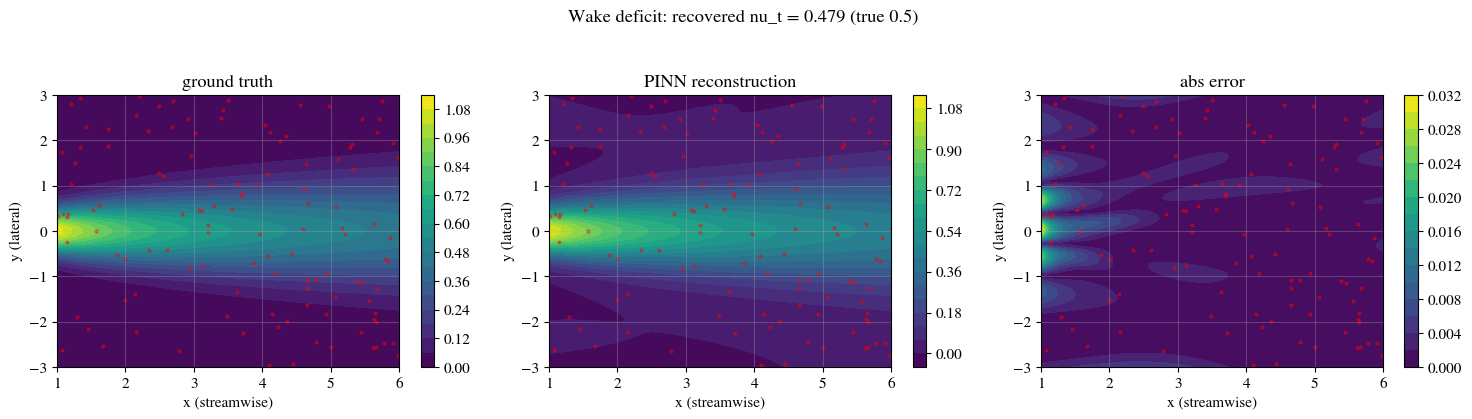

In [4]:
print(f'reconstructed field: relative L2 error {rel_field:.2e}, max abs error {np.abs(dp-dtrue).max():.2e}')

def plot_wind_wake():
    fig, ax = plt.subplots(1,3, figsize=(15,4))
    for a,(f,ttl) in zip(ax, [(dtrue,'ground truth'),(dp,'PINN reconstruction'),
                               (np.abs(dp-dtrue),'abs error')]):
        c=a.contourf(xg, yg, f, 20); fig.colorbar(c, ax=a)
        a.scatter(xd, yd, s=4, c='r', alpha=0.4)
        a.set(title=ttl, xlabel='x (streamwise)', ylabel='y (lateral)')
    fig.suptitle(f'Wake deficit: recovered nu_t = {nu_hat:.3f} (true {NU_T_TRUE})', y=1.04)
    plt.tight_layout()

save_dual(plot_wind_wake, 'wind_wake', FIG)
plt.show()

### How much does the answer depend on the seed?

One run is one draw of the measurement noise, the initialization and the
collocation points. Set `RUN_SEED_SWEEP = True` to repeat the experiment for
`SWEEP_SEEDS` (about five minutes); the table is saved to `data/` and shown
by every later run, labelled as a saved result.

In [5]:
if RUN_SEED_SWEEP:
    rows = []
    for s_ in SWEEP_SEEDS:
        r_ = res if s_ == SEED else run_inverse(s_)
        rows.append(dict(seed=s_, nu_hat=r_['nu_hat'], final_loss=r_['hist'][-1], rel_field=r_['rel_field']))
    os.makedirs(os.path.dirname(SWEEP_FILE), exist_ok=True)
    json.dump(dict(params={k: globals()[k] for k in DEFAULTS if k != 'SEED'}, rows=rows),
              open(SWEEP_FILE, 'w'), indent=1)
if os.path.exists(SWEEP_FILE):
    sweep = json.load(open(SWEEP_FILE))
    print(f'saved seed sweep ({os.path.basename(SWEEP_FILE)}):')
    print(' seed   nu_t    error   final loss   field rel L2')
    for r_ in sweep['rows']:
        print(f" {r_['seed']:4d}  {r_['nu_hat']:.4f}  {abs(r_['nu_hat']-NU_T_TRUE)/NU_T_TRUE:6.1%}"
              f"   {r_['final_loss']:.2e}     {r_['rel_field']:.2e}")
    errs = [abs(r_['nu_hat']-NU_T_TRUE)/NU_T_TRUE for r_ in sweep['rows']]
    print(f'nu_t error: median {np.median(errs):.1%}, range {min(errs):.1%} - {max(errs):.1%}')

saved seed sweep (pinn_wind_pde_seed_sweep.json):
 seed   nu_t    error   final loss   field rel L2
    0  0.4789    4.2%   2.22e-03     1.05e-02
    1  0.4649    7.0%   2.19e-03     1.19e-02
    2  0.4061   18.8%   4.80e-03     3.22e-02
    3  0.4680    6.4%   1.61e-03     1.15e-02
    4  0.4178   16.4%   3.34e-03     2.96e-02
nu_t error: median 7.0%, range 4.2% - 18.8%


In [6]:
assert np.isfinite(hist).all() and hist[-1] < 1e-2
assert abs(nu_hat - NU_T_TRUE)/NU_T_TRUE < 0.25, "nu_t recovered within 25 % (the seed sweep spans up to ~20 %)"
assert rel_field < 0.1, f"field relative L2 error {rel_field:.2e}"
if AT_DEFAULTS:
    # numbers quoted in notes/applications.tex
    assert abs(nu_hat - NU_T_TRUE)/NU_T_TRUE < 0.05, f"nu_t {nu_hat:.4f}"
    print(f'chapter numbers: loss {hist[0]:.1f} -> {hist[-1]:.1e}, nu_t {nu_hat:.3f}, field rel L2 {rel_field:.1e}')
else:
    print('regression check skipped (parameters differ from the slide defaults)')

chapter numbers: loss 10.8 -> 2.2e-03, nu_t 0.479, field rel L2 1.1e-02


**Outlook.** With a calibrated, *differentiable* wake, the same network drops into a gradient-based optimizer for wake steering / layout — and the cost of the high-fidelity solve it replaces motivates the FNO (module 26) and ROM (module 19) lectures.